In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

columns = ["Income", "DTI", "LoanAmount", "CreditScore", "EmploymentLength", "Purpose", "HomeOwnership"]
df = pd.read_csv("../data/processed/loans_clean.csv", usecols=columns)
X_pca = np.load("../data/processed/X_pca.npy")
sample_idx = np.load("../data/processed/sample_idx.npy")
labels_kmeans = np.load("../data/processed/labels_kmeans.npy")

K_COMPARE = 5          # EDIT: the k you chose for K-Means

In [2]:
HIER_N = 5_000
hier_idx = sample_idx[:HIER_N]
X_hier = X_pca[hier_idx]

distances = pdist(X_hier)          # the distance between every pair of the 5,000 borrowers

linkages, rows = {}, []
for method in ["ward", "complete", "average", "single"]:
    Z = linkage(distances, method=method)
    correlation, _ = cophenet(Z, distances)
    linkages[method] = Z
    rows.append({"linkage": method, "cophenetic_correlation": round(correlation, 3)})

pd.DataFrame(rows).set_index("linkage")

,cophenetic_correlation
linkage,
ward,0.391
complete,0.432
average,0.514
single,0.530


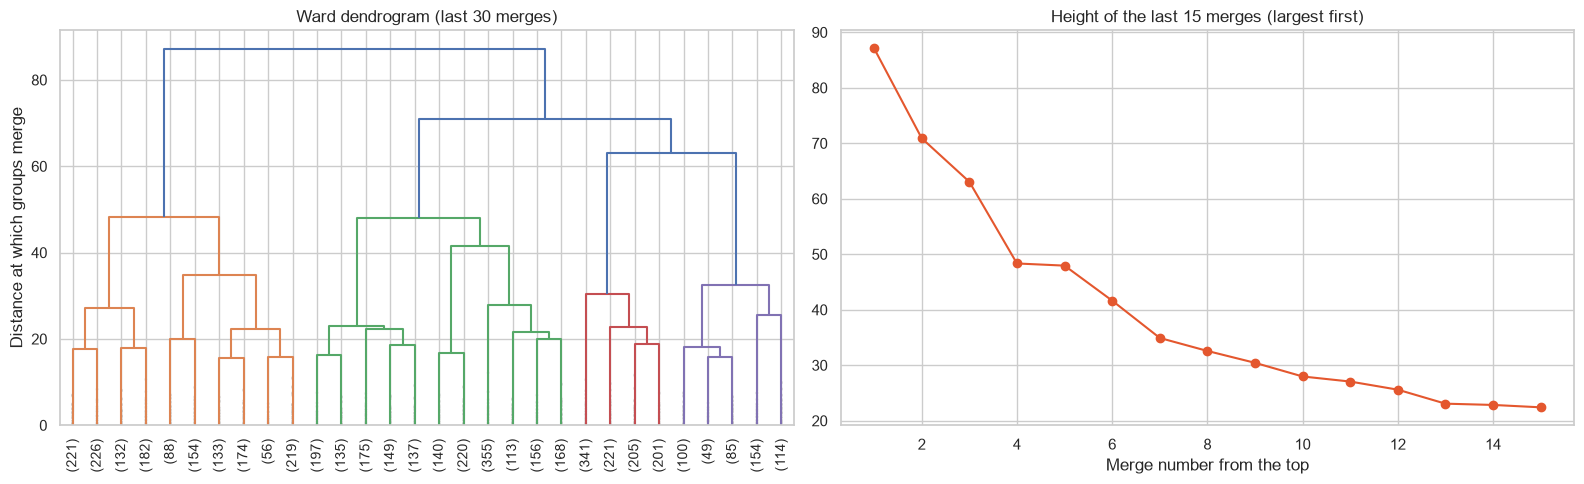

In [3]:
Z = linkages["ward"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True, ax=axes[0])
axes[0].set_title("Ward dendrogram (last 30 merges)")
axes[0].set_ylabel("Distance at which groups merge")

heights = Z[-15:, 2][::-1]
axes[1].plot(range(1, 16), heights, marker="o", color="#E4572E")
axes[1].set_title("Height of the last 15 merges (largest first)")
axes[1].set_xlabel("Merge number from the top")
plt.tight_layout()
plt.savefig("../docs/figures/15_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
hier_rows = []
for k in range(2, 11):
    cut_labels = fcluster(Z, t=k, criterion="maxclust")
    hier_rows.append({"k": k, "silhouette": silhouette_score(X_hier, cut_labels, random_state=42)})
print(pd.DataFrame(hier_rows).set_index("k").round(3).T)

hier_labels = fcluster(Z, t=K_COMPARE, criterion="maxclust")
print("\nCluster sizes:", np.bincount(hier_labels)[1:])
print("Agreement with K-Means on the same 5,000 borrowers (ARI):",
      round(adjusted_rand_score(hier_labels, labels_kmeans[hier_idx]), 3))

k              2      3      4      5      6      7      8      9      10
silhouette  0.143  0.139  0.139  0.121  0.118  0.104  0.104  0.108  0.089

Cluster sizes: [ 761  824 1945  968  502]
Agreement with K-Means on the same 5,000 borrowers (ARI): 0.344


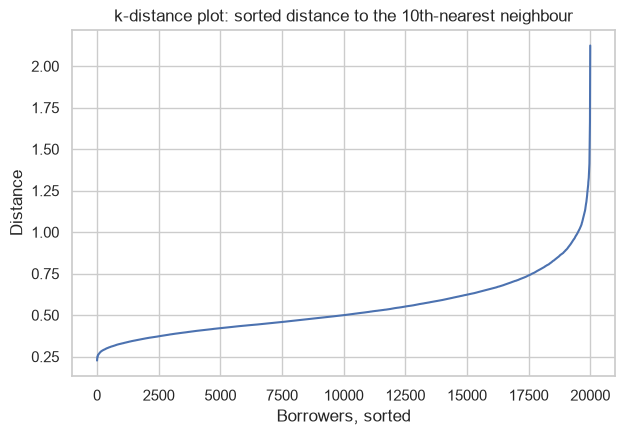

Distance at the 50/80/90/95/98/99th percentile:
[0.5   0.66  0.778 0.89  1.03  1.14 ]


In [5]:
X_db = X_pca[sample_idx]          # 20,000 borrowers
MIN_SAMPLES = 10                  # a common rule of thumb is at least 2 x the number of dimensions (5)

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_db)
neighbor_distances, _ = neighbors.kneighbors(X_db)
k_distances = np.sort(neighbor_distances[:, -1])     # each borrower's distance to its 10th-nearest neighbour

plt.figure(figsize=(7, 4.5))
plt.plot(k_distances)
plt.title("k-distance plot: sorted distance to the 10th-nearest neighbour")
plt.xlabel("Borrowers, sorted")
plt.ylabel("Distance")
plt.savefig("../docs/figures/16_kdistance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Distance at the 50/80/90/95/98/99th percentile:")
print(np.quantile(k_distances, [0.5, 0.8, 0.9, 0.95, 0.98, 0.99]).round(3))

In [6]:
def run_dbscan(eps):
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_db)
    inside = labels != -1
    n_clusters = len(set(labels[inside]))
    biggest = np.bincount(labels[inside]).max() / len(labels) if inside.any() else 0.0
    sil = (silhouette_score(X_db[inside], labels[inside], sample_size=10_000, random_state=42)
           if n_clusters >= 2 else np.nan)
    return labels, {
        "eps": round(eps, 3), "clusters": n_clusters, "noise_share": round(1 - inside.mean(), 3),
        "largest_cluster_share": round(biggest, 3),
        "silhouette_no_noise": round(sil, 3) if sil == sil else np.nan,
    }


results = []
for share in (0.80, 0.90, 0.95, 0.98, 0.99):
    _, row = run_dbscan(float(np.quantile(k_distances, share)))
    row["k_distance_percentile"] = share
    results.append(row)

pd.DataFrame(results).set_index("k_distance_percentile")

,eps,clusters,noise_share,largest_cluster_share,silhouette_no_noise
k_distance_percentile,,,,,
0.80,0.660,4,0.100,0.899,0.104
0.90,0.778,1,0.038,0.962,NaN
0.95,0.890,1,0.014,0.986,NaN
0.98,1.030,1,0.004,0.996,NaN
0.99,1.140,1,0.002,0.998,NaN


In [7]:
EPS_PERCENTILE = 0.98          # EDIT: pick the row from Cell 6 with a small noise share (roughly 1 to 3%)
EPS_FINAL = float(np.quantile(k_distances, EPS_PERCENTILE))

db_labels, summary = run_dbscan(EPS_FINAL)
print(summary)

sample_rows = df.iloc[sample_idx].assign(Noise=(db_labels == -1))
sample_rows.groupby("Noise")[["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]].median().round(1)

{'eps': 1.03, 'clusters': 1, 'noise_share': np.float64(0.004), 'largest_cluster_share': np.float64(0.996), 'silhouette_no_noise': nan}


,Income,LoanAmount,DTI,CreditScore,EmploymentLength
Noise,,,,,
False,65000.0,12000.0,17.7,692.0,6.0
True,62500.0,2000.0,18.0,777.0,4.0


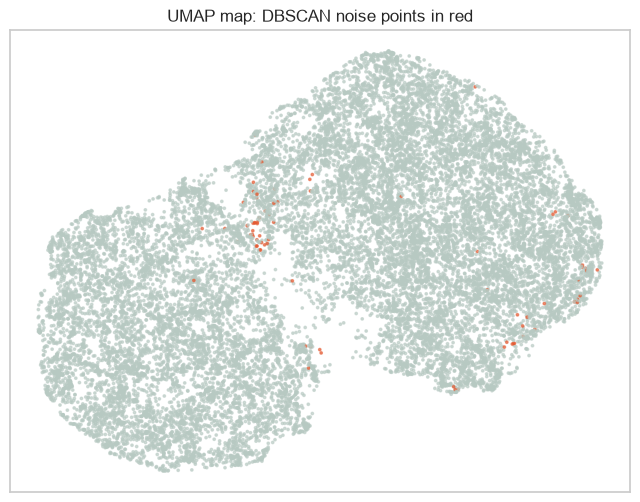

In [8]:
umap_embedding = np.load("../data/processed/umap_embedding.npy")     # same 20,000 borrowers
colors = np.where(db_labels == -1, "#E4572E", "#B7C9C2")

plt.figure(figsize=(8, 6))
plt.scatter(umap_embedding[:, 0], umap_embedding[:, 1], c=colors, s=3, alpha=0.6)
plt.title("UMAP map: DBSCAN noise points in red")
plt.xticks([])
plt.yticks([])
plt.savefig("../docs/figures/17_dbscan_noise_umap.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
np.save("../data/processed/hier_labels.npy", hier_labels)           # for the first 5,000 of sample_idx
np.save("../data/processed/dbscan_labels.npy", db_labels)           # for all 20,000 of sample_idx

with open("../models/dbscan_info.json", "w") as file:
    json.dump({"eps": EPS_FINAL, "min_samples": MIN_SAMPLES, "hierarchical_k": K_COMPARE,
               "linkage": "ward", "hierarchical_sample": HIER_N}, file, indent=2)